In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
sales_header = pd.read_excel(
    r"C:\Users\Hp\Documents\Sales.SalesOrderHeader.xlsx"
)

sales_detail = pd.read_excel(
    r"C:\Users\Hp\Documents\Sales.SalesOrderDetail.xlsx"
)

product = pd.read_excel(
    r"C:\Users\Hp\Documents\Production.Product.xlsx"
)

subcategory = pd.read_excel(
    r"C:\Users\Hp\Documents\Production.ProductSubcategory.xlsx"
)

category = pd.read_excel(
    r"C:\Users\Hp\Documents\Production.ProductCategory.xlsx"
)

In [4]:
print(category)

   ProductCategoryID         Name                               rowguid  \
0                  1        Bikes  CFBDA25C-DF71-47A7-B81B-64EE161AA37C   
1                  2   Components  C657828D-D808-4ABA-91A3-AF2CE02300E9   
2                  3     Clothing  10A7C342-CA82-48D4-8A38-46A2EB089B74   
3                  4  Accessories  2BE3BE36-D9A2-4EEE-B593-ED895D97C2A6   

  ModifiedDate  
0   2008-04-30  
1   2008-04-30  
2   2008-04-30  
3   2008-04-30  


In [12]:
sales_detail.dtypes

SalesOrderID             datetime64[ns]
SalesOrderDetailID                int64
CarrierTrackingNumber            object
OrderQty                          int64
ProductID                         int64
SpecialOfferID                    int64
UnitPrice                       float64
UnitPriceDiscount               float64
LineTotal                       float64
rowguid                          object
ModifiedDate             datetime64[ns]
dtype: object

In [5]:
sales_header.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31465 entries, 0 to 31464
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   SalesOrderID            31465 non-null  datetime64[ns]
 1   RevisionNumber          31465 non-null  int64         
 2   OrderDate               31465 non-null  datetime64[ns]
 3   DueDate                 31465 non-null  datetime64[ns]
 4   ShipDate                31465 non-null  datetime64[ns]
 5   Status                  31465 non-null  int64         
 6   OnlineOrderFlag         31465 non-null  int64         
 7   SalesOrderNumber        31465 non-null  object        
 8   PurchaseOrderNumber     3806 non-null   object        
 9   AccountNumber           31465 non-null  object        
 10  CustomerID              31465 non-null  int64         
 11  SalesPersonID           3806 non-null   float64       
 12  TerritoryID             31465 non-null  int64 

In [6]:
sales_detail.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121317 entries, 0 to 121316
Data columns (total 11 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   SalesOrderID           121317 non-null  datetime64[ns]
 1   SalesOrderDetailID     121317 non-null  int64         
 2   CarrierTrackingNumber  60919 non-null   object        
 3   OrderQty               121317 non-null  int64         
 4   ProductID              121317 non-null  int64         
 5   SpecialOfferID         121317 non-null  int64         
 6   UnitPrice              121317 non-null  float64       
 7   UnitPriceDiscount      121317 non-null  float64       
 8   LineTotal              121317 non-null  float64       
 9   rowguid                121317 non-null  object        
 10  ModifiedDate           121317 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(3), int64(4), object(2)
memory usage: 10.2+ MB


In [8]:
sales_detail.isnull().sum()

SalesOrderID                 0
SalesOrderDetailID           0
CarrierTrackingNumber    60398
OrderQty                     0
ProductID                    0
SpecialOfferID               0
UnitPrice                    0
UnitPriceDiscount            0
LineTotal                    0
rowguid                      0
ModifiedDate                 0
dtype: int64

In [9]:
product_sales = sales_detail.merge(
    product,
    on="ProductID",
    how="left"
)

In [10]:
product_summary = (
    product_sales
    .groupby("Name")
    .agg(
        revenue=("LineTotal", "sum"),
        quantity_sold=("OrderQty", "sum"),
        orders=("SalesOrderID", "nunique")
    )
    .sort_values("revenue", ascending=False)
)

In [11]:
product_summary.head(10)

,revenue,quantity_sold,orders
Name,,,
"Mountain-200 Black, 38",4.400593e+06,2977,1252
"Mountain-200 Black, 42",4.009495e+06,2664,1177
"Mountain-200 Silver, 38",3.693678e+06,2394,1094
"Mountain-200 Silver, 42",3.438479e+06,2234,1040
"Mountain-200 Silver, 46",3.434257e+06,2216,1054
"Mountain-200 Black, 46",3.309673e+06,2111,1059
"Road-250 Black, 44",2.516857e+06,1642,705
"Road-250 Black, 48",2.347656e+06,1498,712
"Road-250 Black, 52",2.012448e+06,1245,667


In [13]:
order_value = (
    sales_detail
    .groupby("SalesOrderID")["LineTotal"]
    .sum()
    .reset_index(name="order_value")
)

In [14]:
order_value.describe()

,SalesOrderID,order_value
count,31465,31465.000000
mean,2062-08-08 00:00:00,3491.065673
min,2019-07-13 00:00:00,1.374000
25%,2041-01-24 00:00:00,56.970000
50%,2062-08-08 00:00:00,782.990000
75%,2084-02-20 00:00:00,2366.960000
max,2105-09-04 00:00:00,163930.394302
std,NaN,11093.452536


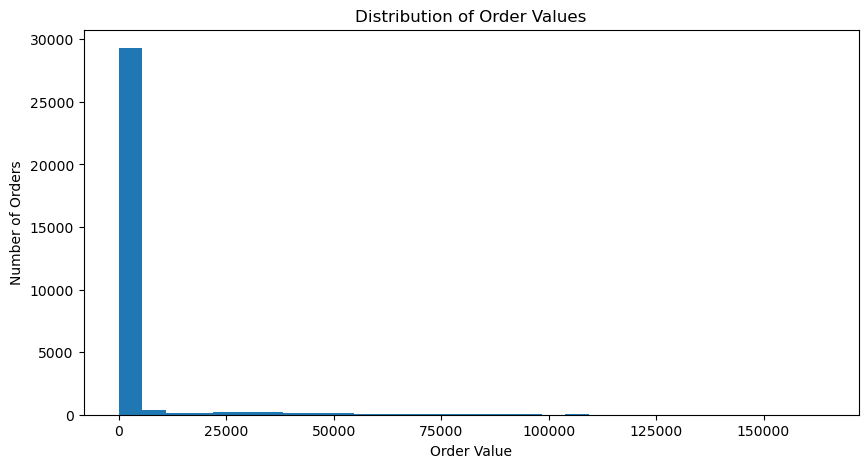

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(order_value["order_value"], bins=30)

plt.title("Distribution of Order Values")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.show()